# 3. MCMC on the same dataset

An independent check of the SBI posterior with `emcee`, for the full model. The likelihood is the
1/3 Gaussian + 2/3 log-normal one of the paper (App. D), with the same priors as the network.

A converged run takes ~50 000 steps (~10 min on a CPU). Here a short run shows how it works.

In [1]:
%matplotlib inline
import warnings; warnings.filterwarnings("ignore")
import numpy as np
import matplotlib.pyplot as plt
from gwbf_foregrounds import FULL, data, mcmc, posterior, stats

In [2]:
ds = data.simulate("full", logGmu=-12, seed=42)
samples, logp, tau, burnin = mcmc.run_mcmc(ds, max_steps=4000, start_logGmu=-12.5, progress=False)
print("samples:", samples.shape, " autocorrelation times:", np.round(tau))

samples: (150848, 7)  autocorrelation times: [232.  16. 100. 139. 229. 288. 329.]


Walkers start away from the truth in log10 Gμ (here −12.5) to test that the chain finds it.
For a converged run, leave `max_steps` at its default; the run stops when the chain is longer
than 50 autocorrelation times and they have settled. `output_file=` saves the chain.

In [3]:
post = posterior.load_posterior("full")
s_sbi = posterior.sample(post, ds, n=10_000, seed=0)
for name, a, b, t in zip(FULL.param_names, samples.T, s_sbi.T, FULL.theta(ds.params)):
    print(f"{name:10s} truth {t:9.4f}   MCMC {np.median(a):9.4f}   SBI {np.median(b):9.4f}")

logGmu     truth  -12.0000   MCMC  -12.0041   SBI  -11.9997
A_p        truth   15.0000   MCMC   15.0023   SBI   15.0014
A_acc      truth    3.0000   MCMC    3.0016   SBI    2.9923
logA_Gal   truth   -7.8400   MCMC   -7.8390   SBI   -7.8385
logA_ExB   truth  -12.3800   MCMC  -12.5825   SBI  -12.4704
logA_ExWB  truth  -11.0554   MCMC  -10.9727   SBI  -10.9900
logA_EMRI  truth    0.0000   MCMC   -0.0661   SBI   -0.0723


precision on Gmu:  MCMC (short run) 21.8 %   SBI 22.2 %


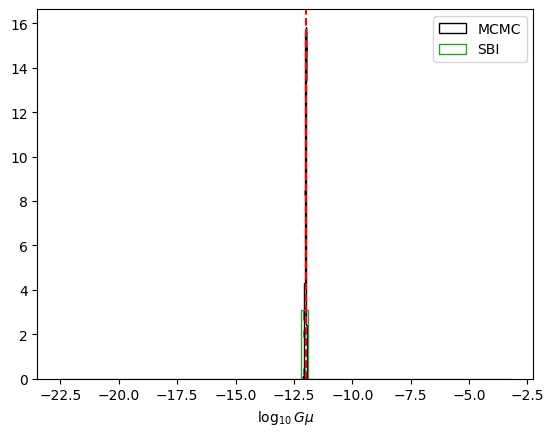

In [4]:
prec_mcmc = stats.precision_from_samples(samples[:, 0], -12)[0]
prec_sbi = stats.precision_from_samples(s_sbi[:, 0], -12)[0]
print(f"precision on Gmu:  MCMC (short run) {prec_mcmc:.1f} %   SBI {prec_sbi:.1f} %")
plt.hist(samples[:, 0], bins=60, density=True, histtype="step", color="k", label="MCMC")
plt.hist(s_sbi[:, 0], bins=60, density=True, histtype="step", color="C2", label="SBI")
plt.axvline(-12, color="red", ls="--"); plt.xlabel(r"$\log_{10} G\mu$"); plt.legend();

From the command line: `gwbf-fg mcmc --logGmu -12` (simulates with seed 42, saves dataset and chain).